# Caffeine & Sleep Time Planner (Set, Logic)
**ปัญหา:** ช่วงสอบนักศึกษาดื่มกาแฟ แต่คาเฟอีนค้างในร่างกายหลายชั่วโมง ทำให้นอนไม่หลับ

**วัตถุประสงค์:** บอกว่าดื่มกาแฟแล้ว **นอนได้ตามเวลาที่ตั้งใจหรือไม่** และ **นอนได้ตั้งแต่กี่โมง**

## สูตร: คาเฟอีนลดลงครึ่งหนึ่งทุก 5 ชั่วโมง
$$C(t) = D \times \left(\tfrac{1}{2}\right)^{t/5}$$
$D$ = คาเฟอีนที่ดื่ม (mg), $t$ = ชั่วโมงหลังดื่ม · นอนได้เมื่อเหลือ **≤ 50 mg** · ไม่ควรดื่มเกิน **400 mg/วัน**

In [1]:
import matplotlib.pyplot as plt

SLEEP_LIMIT = 50   # mg
DAILY_LIMIT = 400  # mg

def caffeine_left(dose, hours):
    return dose * 0.5 ** (hours / 5)

def show_time(hour):          # 25 -> "01:00"
    return f"{hour % 24:02d}:00"

Matplotlib is building the font cache; this may take a moment.


## หัวข้อที่ 1: Set (Lab 2)
- $A$ = ชั่วโมงที่คาเฟอีน ≤ 50 mg (**นอนได้**)
- $B$ = ชั่วโมงที่ **อยากนอน** (ตั้งแต่เข้านอนจนก่อนตื่น)
- $A \cap B$ = ชั่วโมงที่นอนได้จริง · $B - A$ = ชั่วโมงที่อยากนอนแต่ยังนอนไม่ได้

In [2]:
def make_sets(dose, drink, bed, wake):
    if bed < drink:        # นอนหลังเที่ยงคืน = วันถัดไป
        bed += 24
    while wake <= bed:     # ตื่นหลังเวลานอน
        wake += 24

    A = set()
    for h in range(drink, wake + 1):
        if caffeine_left(dose, h - drink) <= SLEEP_LIMIT:
            A.add(h)
    B = set(range(bed, wake))
    return A, B

## หัวข้อที่ 2: Logic (Lab 3)
- $p$: ช่วงที่อยากนอนปลอดภัยทั้งหมด ($B \subseteq A$)
- $q$: ดื่มไม่เกิน 400 mg
- **นอนได้ ⇔ $p \land q$** ถ้านอนไม่ได้ ดูว่า $\lnot p$ หรือ $\lnot q$ เป็นจริง

In [3]:
def check_sleep(dose, A, B):
    p = B <= A                 # B ⊆ A
    q = dose <= DAILY_LIMIT
    return p, q

In [4]:
def ask_number(text, low, high, input_fn=input):
    while True:
        try:
            value = int(input_fn(text))
            if low <= value <= high:
                return value
        except ValueError:
            pass
        print(f"กรุณากรอกตัวเลข {low}-{high}")


def plan(dose, drink, bed, wake, show_plot=True):
    A, B = make_sets(dose, drink, bed, wake)
    p, q = check_sleep(dose, A, B)

    # ตาราง
    print("เวลา  | คาเฟอีน (mg)")
    for h in range(drink, max(B) + 2):
        print(f"{show_time(h)} | {caffeine_left(dose, h - drink):7.2f}")

    # Set
    print("\nA ∩ B (นอนได้จริง)   =", [show_time(h) for h in sorted(A & B)])
    print("B − A (ยังนอนไม่ได้) =", [show_time(h) for h in sorted(B - A)])

    # Logic
    print(f"\np = {p}, q = {q}, p and q = {p and q}")
    if p and q:
        print("✅ นอนได้ตามเวลาที่ตั้งใจ")
    if not p:
        print("❌ not p: คาเฟอีนยังเกิน 50 mg ตอนนอน")
    if not q:
        print("❌ not q: ดื่มเกิน 400 mg ต่อวัน")
    if A:
        print("⏰ นอนได้ตั้งแต่", show_time(min(A)))

    # กราฟ
    if show_plot:
        hours = list(range(drink, max(B) + 2))
        plt.plot(hours, [caffeine_left(dose, h - drink) for h in hours], marker="o", label="Caffeine")
        plt.axhline(SLEEP_LIMIT, color="red", linestyle="--", label="50 mg limit")
        plt.axvline(min(B), color="gray", linestyle=":", label="Bedtime")
        plt.xticks(hours, [show_time(h) for h in hours], rotation=60)
        plt.ylabel("Caffeine (mg)")
        plt.legend()
        plt.grid(True)
        plt.show()
    return p, q


def main():
    dose = ask_number("คาเฟอีนที่ดื่ม (mg): ", 1, 1000)
    drink = ask_number("เวลาที่ดื่ม (0-23): ", 0, 23)
    bed = ask_number("เวลาที่อยากนอน (0-23): ", 0, 23)
    wake = ask_number("เวลาที่ตื่น (0-23): ", 0, 23)
    plan(dose, drink, bed, wake)

## ทดสอบ 3 กรณี

In [5]:
print("=== กรณี 1: 96 mg ดื่ม 12:00 นอน 22:00 ===")
assert plan(96, 12, 22, 6, show_plot=False) == (True, True)     # นอนได้

print("\n=== กรณี 2: 96 mg ดื่ม 20:00 นอน 23:00 ===")
assert plan(96, 20, 23, 7, show_plot=False) == (False, True)    # not p

print("\n=== กรณี 3: 450 mg ดื่ม 06:00 นอน 23:00 ===")
assert plan(450, 6, 23, 7, show_plot=False) == (True, False)    # not q

print("\n✔ ผ่านทั้ง 3 กรณี")

=== กรณี 1: 96 mg ดื่ม 12:00 นอน 22:00 ===
เวลา  | คาเฟอีน (mg)
12:00 |   96.00
13:00 |   83.57
14:00 |   72.75
15:00 |   63.34
16:00 |   55.14
17:00 |   48.00
18:00 |   41.79
19:00 |   36.38
20:00 |   31.67
21:00 |   27.57
22:00 |   24.00
23:00 |   20.89
00:00 |   18.19
01:00 |   15.83
02:00 |   13.78
03:00 |   12.00
04:00 |   10.45
05:00 |    9.09
06:00 |    7.92

A ∩ B (นอนได้จริง)   = ['22:00', '23:00', '00:00', '01:00', '02:00', '03:00', '04:00', '05:00']
B − A (ยังนอนไม่ได้) = []

p = True, q = True, p and q = True
✅ นอนได้ตามเวลาที่ตั้งใจ
⏰ นอนได้ตั้งแต่ 17:00

=== กรณี 2: 96 mg ดื่ม 20:00 นอน 23:00 ===
เวลา  | คาเฟอีน (mg)
20:00 |   96.00
21:00 |   83.57
22:00 |   72.75
23:00 |   63.34
00:00 |   55.14
01:00 |   48.00
02:00 |   41.79
03:00 |   36.38
04:00 |   31.67
05:00 |   27.57
06:00 |   24.00
07:00 |   20.89

A ∩ B (นอนได้จริง)   = ['01:00', '02:00', '03:00', '04:00', '05:00', '06:00']
B − A (ยังนอนไม่ได้) = ['23:00', '00:00']

p = False, q = True, p and q = False
❌ not p: ค

**สรุปผล:** กรณี 1 นอนได้ · กรณี 2 คาเฟอีนยังสูงตอน 23:00 ต้องรอถึง 01:00 · กรณี 3 คาเฟอีนลดทัน แต่ดื่มเกิน 400 mg

**ข้อจำกัด:** ใช้ครึ่งชีวิต 5 ชม. เท่ากันทุกคน, ดื่มครั้งเดียว, คิดทีละชั่วโมง — เป็นค่าประมาณ ไม่ใช่คำแนะนำทางการแพทย์

## สาธิต: กรอกข้อมูลเอง

คาเฟอีนที่ดื่ม (mg):  100
เวลาที่ดื่ม (0-23):  15
เวลาที่อยากนอน (0-23):  21
เวลาที่ตื่น (0-23):  5.30


กรุณากรอกตัวเลข 0-23


เวลาที่ตื่น (0-23):  6


เวลา  | คาเฟอีน (mg)
15:00 |  100.00
16:00 |   87.06
17:00 |   75.79
18:00 |   65.98
19:00 |   57.43
20:00 |   50.00
21:00 |   43.53
22:00 |   37.89
23:00 |   32.99
00:00 |   28.72
01:00 |   25.00
02:00 |   21.76
03:00 |   18.95
04:00 |   16.49
05:00 |   14.36
06:00 |   12.50

A ∩ B (นอนได้จริง)   = ['21:00', '22:00', '23:00', '00:00', '01:00', '02:00', '03:00', '04:00', '05:00']
B − A (ยังนอนไม่ได้) = []

p = True, q = True, p and q = True
✅ นอนได้ตามเวลาที่ตั้งใจ
⏰ นอนได้ตั้งแต่ 20:00


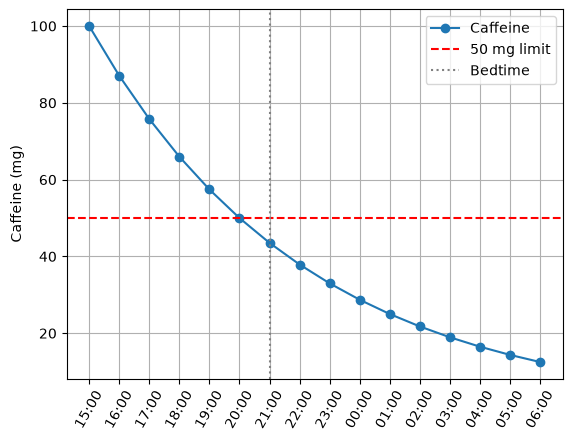

In [7]:
main()#lihigyguS